In [144]:
def count_self_avoiding_walks(L):
    def is_valid_move(x, y, path):
        return (x, y) not in path

    def explore(x, y, path, length):
        if length == 0:
            return 1
        count = 0
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nx, ny = x + dx, y + dy
            if is_valid_move(nx, ny, path):
                count += explore(nx, ny, path | {(nx, ny)}, length - 1)
        return count

    start_x, start_y = 0, 0
    path = {(start_x, start_y)}
    return explore(start_x, start_y, path, L)

# Example usage:
L = 10
total_walks = count_self_avoiding_walks(L)
print(f"Total number of self-avoiding walks of length {L}: {total_walks}")

#takes longer than 30 sec to find L = 17

Total number of self-avoiding walks of length 10: 44100


In [145]:
import numpy as np

def generate_random_walk(L):
    x, y = 0, 0
    path = [(x, y)]
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for _ in range(L):
        dx, dy = directions[np.random.randint(4)]
        x, y = x + dx, y + dy
        path.append((x, y))
    return path

In [257]:
def is_self_avoiding_walk(walk, expected_length=None):
    """
    Check if the walk is self-avoiding.
    If `expected_length` is provided, also check that the walk has length `expected_length + 1`.
    """
    visited_positions = set()
    for position in walk:
        if position in visited_positions:
            return False
        visited_positions.add(position)

    if expected_length is not None and len(walk) != expected_length + 1:
        return False

    return True

In [147]:
N = 1000000
L = 4

walks = [generate_random_walk(L) for _ in range(N)]
self_avoiding_walks = [walk for walk in walks if is_self_avoiding_walk(walk)]
p = len(self_avoiding_walks) / N
print(f"Estimated fraction of self-avoiding walks of length {L}: {p}")

Estimated fraction of self-avoiding walks of length 4: 0.390964


In [148]:
def generate_self_avoiding_walk(L):
    x, y = 0, 0
    path = [(x, y)]
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for _ in range(L):
        valid_moves = [(x + dx, y + dy) for dx, dy in directions if (x + dx, y + dy) not in path]
        if not valid_moves:
            path.extend([path[-1]] * (L - len(path)))
            break
        x, y = valid_moves[np.random.randint(len(valid_moves))]
        path.append((x, y))
    return path

# Example usage:
L = 4
walk = generate_self_avoiding_walk(L)
print(f"Generated self-avoiding walk of length {L}: {walk}")

Generated self-avoiding walk of length 4: [(0, 0), (-1, 0), (-1, -1), (-2, -1), (-2, -2)]


In [149]:
def importance_sampling_estimate(L, N):
    """Estimate C_L using importance sampling."""
    
    # Generate random walks and count self-avoiding ones
    random_walks = [generate_random_walk(L) for _ in range(N)]
    num_saw_in_random = sum(1 for walk in random_walks if is_self_avoiding_walk(walk))
    p_random = num_saw_in_random / N  # Probability of self-avoiding walk in basic Monte Carlo
    
    # Generate self-avoiding walks
    saw_walks = [generate_self_avoiding_walk(L) for _ in range(N)]
    num_saw_in_proposed = sum(1 for walk in saw_walks if is_self_avoiding_walk(walk))
    p_proposed = num_saw_in_proposed / N  # Probability of self-avoiding walk in proposed Monte Carlo

    # Compute importance sampling estimate
    if p_proposed == 0:  # Avoid division by zero
        return None
    
    importance_ratio = p_random / p_proposed
    C_L = importance_ratio * 4**L  # Since first step has 4 choices
    
    return C_L

# Example usage
L = 15
N = 100000  # Number of samples
C_L_estimate = importance_sampling_estimate(L, N)
print(f"Estimated C_{L}: {C_L_estimate:.4f}")

Estimated C_15: 6083995.7087


In [259]:
def compute_rosenbluth_weight(walk, expected_length=None):
    """
    Compute the importance weight for a walk.
    If the walk is not self-avoiding, the weight is 0.
    Otherwise, the weight is 1 / Q(x), where Q(x) is the probability of generating the walk
    using generate_self_avoiding_walk(L).
    """
    # First, check if the walk is self-avoiding
    if not is_self_avoiding_walk(walk, expected_length):
        return 0  # Weight is 0 for non-self-avoiding walks

    L = len(walk) - 1

    weight = 1.0
    x, y = 0, 0
    path = [(x, y)]
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for step in range(L):
        valid_moves = [(x + dx, y + dy) for dx, dy in directions if (x + dx, y + dy) not in path]
        num_valid_moves = len(valid_moves)
        # Update the weight
        weight *= num_valid_moves
        # Move to the next position in the walk
        x, y = walk[step + 1]
        path.append((x, y))
    # The weight is 1 / Q(x), where Q(x) is the product of (1 / num_valid_moves) at each step
    return weight

def rosenbluth_estimate(L, N):
    total_weight = 0
    for _ in range(N):
        walk = generate_self_avoiding_walk(L)
        if walk is not None:  # Ensure the walk is valid
            weight = compute_rosenbluth_weight(walk, expected_length=L)
            total_weight += weight
    # Estimate the total number of SAWs
    return total_weight / N

# Parameters
L = 10 # Length of the walk
N = 100000  # Number of samples

# Estimate the number of SAWs
estimated_num_saws = rosenbluth_estimate(L, N)
print(f"Estimated number of SAWs of length {L}: {estimated_num_saws}")

Estimated number of SAWs of length 10: 44084.92392


In [275]:
import matplotlib.pyplot as plt
actual = [count_self_avoiding_walks(L) for L in range(1, 16)]
predicted = [round(importance_sampling_estimate(L, N)) for L in range(1, 16)]
print(predicted)
print(actual)

[4, 12, 36, 100, 284, 780, 2173, 5917, 16246, 44086, 120315, 324468, 882140, 2374347, 6417844]
[4, 12, 36, 100, 284, 780, 2172, 5916, 16268, 44100, 120292, 324932, 881500, 2374444, 6416596]


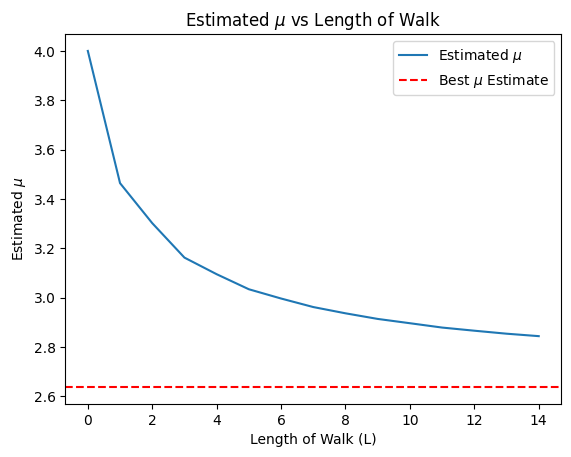

In [256]:
#use predicted values to predict mu
#mu is estimated as C_L ** (1/L)

mu_estimate = [predicted[i] ** (1/(i+1)) for i in range(len(predicted))]
plt.plot(mu_estimate, label='Estimated $\mu$')
plt.axhline(y=2.638158533032790, color='r', linestyle='--', label='Best $\mu$ Estimate')
plt.xlabel('Length of Walk (L)')
plt.ylabel('Estimated $\mu$')
plt.title('Estimated $\mu$ vs Length of Walk')
plt.legend()
plt.show()

In [261]:
#concatenate 2 SAWs
def concatenate_saws(saw1, saw2):
    #find the last point of saw1
    last_point = saw1[-1]
    #exclude first point of saw2
    saw2 = saw2[1:]
    #add the x and y coordinated of the last point to every point of saw2
    saw2 = [(x + last_point[0], y + last_point[1]) for x, y in saw2]
    #concatenate the two lists
    return saw1 + saw2

# Example usage
saw1 = generate_self_avoiding_walk(4)
saw2 = generate_self_avoiding_walk(4)
concatenated_saw = concatenate_saws(saw1, saw2)
print(concatenated_saw)

[(0, 0), (0, -1), (1, -1), (1, -2), (2, -2), (2, -3), (2, -4), (2, -5), (3, -5)]


In [265]:
def rotate_left(point):
    x, y = point
    return -y, x

def rotate_right(point):
    x, y = point
    return y, -x

def rotate_180(point):
    x, y = point
    return -x, -y

def apply_transformation(walk, pivot_index, transform_fn):
    pivot = walk[pivot_index]
    x0, y0 = pivot
    new_segment = []

    for x, y in walk[pivot_index + 1:]:
        dx, dy = x - x0, y - y0
        tx, ty = transform_fn((dx, dy))
        new_segment.append((x0 + tx, y0 + ty))

    return walk[:pivot_index + 1] + new_segment

def generate_initial_walk(L):
    """Random initial walk to reduce shared structure"""
    walk = [(0, 0)]
    direction_choices = [(1,0), (-1,0), (0,1), (0,-1)]

    while len(walk) < L + 1:
        x, y = walk[-1]
        np.random.shuffle(direction_choices)
        for dx, dy in direction_choices:
            new_point = (x + dx, y + dy)
            if new_point not in walk:
                walk.append(new_point)
                break
        else:
            # restart if stuck
            walk = [(0, 0)]
    return walk

In [266]:
def generate_saw_samples(L, N):
    samples = []

    for _ in range(N):
        walk = generate_initial_walk(L)
        accepted = 0

        # Do a few pivots to decorrelate even if initial walk is already SAW
        while accepted < L:
            pivot_index = np.random.randint(1, L)
            transformation = np.random.choice([rotate_left, rotate_right, rotate_180])
            walk_new = apply_transformation(walk, pivot_index, transformation)
            if is_self_avoiding_walk(walk_new, expected_length=L):
                walk = walk_new
                accepted += 1

        samples.append(walk)

    return samples

In [267]:
def estimate_concatenation_prob(L1, L2, N):
    count = 0
    saws1 = generate_saw_samples(L1, N)
    saws2 = generate_saw_samples(L2, N)
    
    for saw1, saw2 in zip(saws1, saws2):
        concat = concatenate_saws(saw1, saw2)
        if is_self_avoiding_walk(concat, expected_length=L1 + L2):
            count += 1

    return count / N

In [294]:
def estimate_C_L(L1, L2, N):
    prob = estimate_concatenation_prob(L1, L2, N)
    C_L1 = count_self_avoiding_walks(L1)
    C_L2 = count_self_avoiding_walks(L2)
    print(prob)
    return prob * C_L1 * C_L2

# Example usage
L1 = 10
L2 = 10
N = 100000
estimated_C_L = estimate_C_L(L1, L2, N)
print(f"Estimated C_{L1 + L2}: {estimated_C_L:.4f}")

0.46766560038909777
Estimated C_20: 909520736.2927


In [268]:
#diff variation of estimate_concat_prob where we sample to N success samples

def estimate_concatenation_prob(L1, L2, valid_target=1000):
    valid_count = 0
    total_attempts = 0

    while valid_count < valid_target:
        saw1 = generate_saw_samples(L1, 1)[0]
        saw2 = generate_saw_samples(L2, 1)[0]
        concat = concatenate_saws(saw1, saw2)
        total_attempts += 1
        if is_self_avoiding_walk(concat, expected_length=L1 + L2):
            valid_count += 1

    return valid_count / total_attempts

  → Concatenation probability: 0.394477
  → Concatenation probability: 0.310270
  → Concatenation probability: 0.236742
  → Concatenation probability: 0.196232
  → Concatenation probability: 0.154154
{20: 897697164, 40: 3.178935693308256e+17, 80: 3.135473826307553e+34, 160: 2.32746120157664e+68, 320: 1.063005424812515e+136, 640: 1.741915420349677e+271}
[2.803215543834559, 2.738779342914488, 2.6990056254762456, 2.674810475079389, 2.661233142179519, 2.6534695289669683]


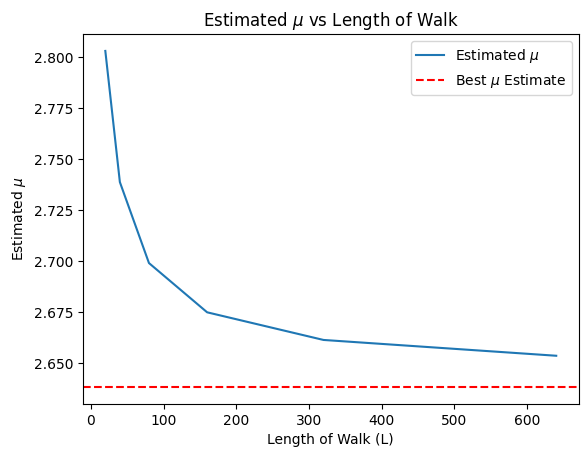

In [300]:
C_L_recursion = {20: 897697164}

def recursive_estimate(L1, L2):
    for _ in range(5):
        prob = estimate_concatenation_prob(L1, L2, valid_target=1000)
        print(f"  → Concatenation probability: {prob:.6f}")
        C_L1 = C_L_recursion[L1]
        C_L2 = C_L_recursion[L2]
        L = L1 + L2
        C_L = prob * C_L1 * C_L2
        C_L_recursion[L] = C_L
        L1 = L
        L2 = L

recursive_estimate(20, 20)

mu_recursion = []
lengths = []

for L in sorted(C_L_recursion):
    mu_L = C_L_recursion[L] ** (1 / L)
    mu_recursion.append(mu_L)
    lengths.append(L)

print(C_L_recursion)
print(mu_recursion)

plt.plot(lengths, mu_recursion, label='Estimated $\mu$')
plt.axhline(y=2.638158533032790, color='r', linestyle='--', label='Best $\mu$ Estimate')
plt.xlabel('Length of Walk (L)')
plt.ylabel('Estimated $\mu$')
plt.title('Estimated $\mu$ vs Length of Walk')
plt.legend()
plt.show()

In [270]:
def count_valid_extensions(walk):
    x, y = walk[-1]
    directions = [(1,0), (-1,0), (0,1), (0,-1)]
    return sum((x + dx, y + dy) not in walk for dx, dy in directions)

def resample_population(population, weights, N):
    weights = np.array(weights, dtype=np.float64)
    total_weight = np.sum(weights)
    if total_weight == 0:
        raise ValueError("All weights are zero. Population collapsed.")

    probabilities = weights / total_weight
    indices = np.random.choice(len(population), size=N, p=probabilities)
    return [population[i] for i in indices]

def extend_walks(population):
    new_population = []
    directions = [(1, 0), (-1, 0), (0, 1), (0, -1)]

    for walk in population:
        if len(walk) < 2:
            prev_direction = (1, 0)  # Default starting direction
        else:
            x1, y1 = walk[-2]
            x2, y2 = walk[-1]
            prev_direction = (x2 - x1, y2 - y1)

        # Disallow backtracking
        allowed_directions = [d for d in directions if d != (-prev_direction[0], -prev_direction[1])]
        dx, dy = allowed_directions[np.random.randint(0, len(allowed_directions))]

        x, y = walk[-1]
        new_point = (x + dx, y + dy)
        new_walk = walk + [new_point]

        new_population.append(new_walk)

    return new_population

def diversify_population(population):
    seen = set()
    diversified = []

    for walk in population:
        walk_tuple = tuple(walk)
        if walk_tuple not in seen:
            diversified.append(walk)
            seen.add(walk_tuple)
        else:
            # Apply up to L//5 pivots to attempt diversification
            new_walk = walk
            L = len(walk) - 1
            success = False

            for _ in range(max(1, L)):
                pivot_index = np.random.randint(1, L)
                transform = np.random.choice([rotate_left, rotate_right, rotate_180])
                candidate = apply_transformation(new_walk, pivot_index, transform)
                if is_self_avoiding_walk(candidate, expected_length=L):
                    new_walk = candidate
                    success = True

            if success and tuple(new_walk) not in seen:
                diversified.append(new_walk)
                seen.add(tuple(new_walk))
            else:
                # Fallback: generate a new SAW of the same length
                regenerated = generate_saw_samples(len(walk), 1)[0]
                diversified.append(regenerated)
                seen.add(tuple(regenerated))

    return diversified

In [271]:
def estimate_mu_step(population, expected_length=None):
    weights = []
    for walk in population:
        if is_self_avoiding_walk(walk, expected_length):
            weights.append(count_valid_extensions(walk))
        else:
            weights.append(0)
    return np.mean(weights), weights

def recursive_mu_estimation(L0, N, steps):
    population = generate_saw_samples(L0, N)
    mus = []
    lengths = [L0]

    for step in range(steps):
        mu, weights = estimate_mu_step(population, expected_length=lengths[-1])
        mus.append(mu)
        lengths.append(lengths[-1] + 1)

        population = extend_walks(population)
        sampling_weights = [1 if is_self_avoiding_walk(walk, expected_length=lengths[-1]) else 0 for walk in population]
        population = resample_population(population, sampling_weights, N)
        population = diversify_population(population)

    return lengths[1:], mus

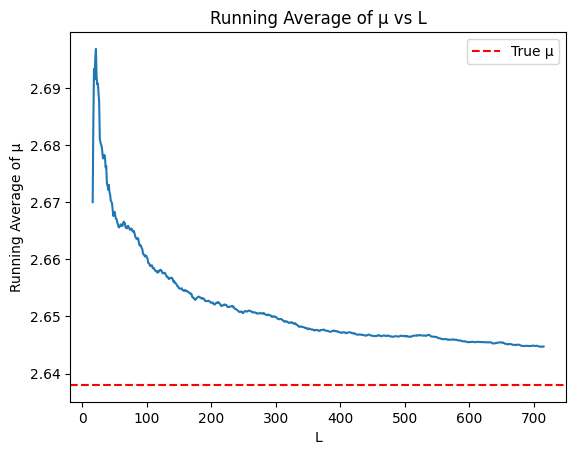

In [287]:
lengths, mu_estimates = recursive_mu_estimation(L0 = 15, N = 1000, steps = 700)

mus_running_avg = np.cumsum(mu_estimates) / np.arange(1, len(mu_estimates) + 1)
plt.plot(lengths, mus_running_avg)
plt.axhline(2.638, color='red', linestyle='--', label='True μ')
plt.xlabel("L")
plt.ylabel("Running Average of μ")
plt.legend()
plt.title("Running Average of μ vs L")
plt.show()

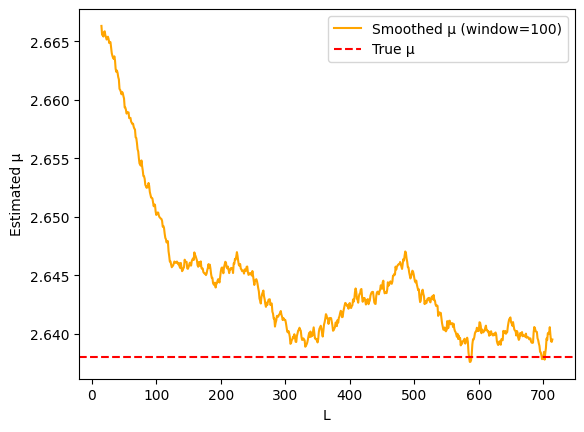

In [305]:
def centered_running_average(data, window_size=10):
    n = len(data)
    smoothed = []

    for i in range(n):
        # Determine the window bounds
        half_window = window_size // 2
        start = max(0, i - half_window)
        end = min(n, i + half_window + 1)

        # Average over the current window
        avg = np.mean(data[start:end])
        smoothed.append(avg)

    return np.array(smoothed)

smoothed_mus = centered_running_average(mu_estimates, window_size=100)
plt.plot(range(15, 715), smoothed_mus, color="orange", label="Smoothed μ (window=100)")
plt.axhline(2.638, color='red', linestyle='--', label='True μ')
plt.xlabel("L")
plt.ylabel("Estimated μ")
plt.legend()
plt.show()